In [3]:
import pandas as pd
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tensorflow as tf

**Data Loading**

In [4]:
data = pd.read_csv("train-test.csv")

**Data Exploration**

In [5]:
data.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [7]:
data.dropna(inplace=True)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 47327 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       47327 non-null  object 
 1   pickup        47327 non-null  object 
 2   delivery      47327 non-null  object 
 3   pickup_lat    47327 non-null  float64
 4   pickup_lon    47327 non-null  float64
 5   delivery_lat  47327 non-null  float64
 6   delivery_lon  47327 non-null  float64
 7   distance      47327 non-null  float64
 8   equipment     47327 non-null  object 
 9   weight        47327 non-null  float64
 10  date          47327 non-null  object 
 11  market_index  47327 non-null  float64
 12  quote_signal  47327 non-null  float64
 13  posted_rate   47327 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.4+ MB


In [10]:
data['equipment'].value_counts()

,count
equipment,
Dry Van,26825
Reefer,11876
Flatbed,8626


In [12]:
data.head()

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal,posted_rate,equipment_Dry Van,equipment_Flatbed,equipment_Reefer
0,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,30658.0,2025-01-01,0.95684,2.39595,645.41,True,False,False
1,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,17555.0,2025-01-01,0.97623,2.43355,679.97,False,False,True
2,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,31721.0,2025-01-01,1.00971,1.84491,1802.54,True,False,False
3,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,32333.0,2025-01-01,0.94518,1.87712,1827.28,True,False,False
4,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,35183.0,2025-01-01,0.98480,2.56300,1380.28,False,False,True


In [13]:
data['pickup'].value_counts()

,count
pickup,
Oklahoma City,1226
Lexington,1193
Bakersfield,1174
Fort Wayne,1155
Hartford,1132
...,...
Washington,334
Detroit,331
St. Louis,315


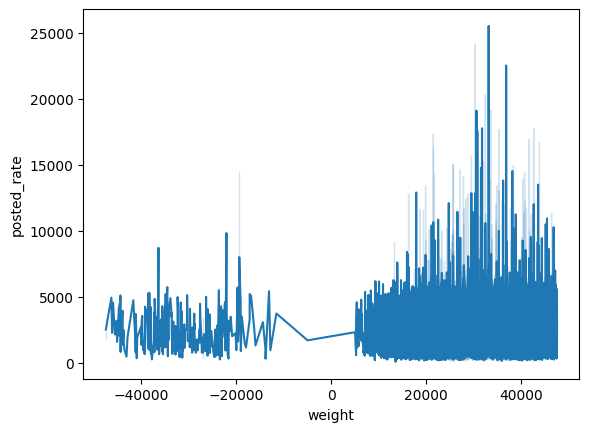

In [ ]:
sns.lineplot(data = data,x = 'weight',y ='posted_rate')
plt.show()

In [14]:
data[data["weight"] < 0]["weight"].describe()

,weight
count,289.000000
mean,-31799.557093
std,8271.416886
min,-47500.000000
25%,-37318.000000
50%,-31935.000000
75%,-25982.000000
max,-5000.000000


In [15]:
data["weight"].value_counts().sort_index().head(20)

,count
weight,
-47500.0,13
-46334.0,1
-46187.0,1
-45975.0,1
-45588.0,1
-45221.0,1
-45128.0,1
-44754.0,1
-44572.0,1


In [16]:
(data["weight"] < 0).sum()

np.int64(289)

In [17]:
data[data["weight"] < 0][
    ["pickup", "delivery", "weight", "distance","market_index",	"quote_signal", "posted_rate","equipment_Dry Van","equipment_Flatbed","equipment_Reefer"]
].head(30)

,pickup,delivery,weight,distance,market_index,quote_signal,posted_rate,equipment_Dry Van,equipment_Flatbed,equipment_Reefer
68,Amarillo,Dayton,-36559.0,1334.2,0.96102,2.11777,2831.27,False,False,True
204,Fresno,Tucson,-26670.0,496.2,0.96903,2.13155,1046.92,True,False,False
206,Columbia,Raleigh,-20003.0,411.3,0.94800,2.31682,959.15,False,False,True
225,Greensboro,Lubbock,-23981.0,1317.4,1.00820,2.13918,2836.00,False,False,True
376,Madison,Providence,-41397.0,1331.1,0.94787,1.91867,2522.54,True,False,False
446,Albuquerque,Albany,-37215.0,2438.3,0.96575,1.96959,4841.57,False,False,True
495,Montgomery,Dayton,-31214.0,715.9,0.85153,2.03947,1473.78,True,False,False
641,Tulsa,Indianapolis,-41023.0,582.4,0.81988,2.22721,1264.33,True,False,False
806,Cincinnati,Buffalo,-28320.0,676.1,0.79158,1.95680,1307.76,True,False,False
1093,Cincinnati,Albany,-25153.0,1058.5,0.89891,1.81081,1907.83,True,False,False


In [19]:
data[["posted_rate", "weight", "distance",
    "market_index", "quote_signal", "pickup_lon","pickup_lat","delivery_lon","delivery_lat"]].corr()["posted_rate"].sort_values()

,posted_rate
delivery_lon,-0.256771
pickup_lon,-0.254759
delivery_lat,-0.091595
pickup_lat,-0.091537
quote_signal,-0.039868
market_index,0.033716
weight,0.041589
distance,0.908282
posted_rate,1.000000


**Feature Engineering & Data cleaning**

In [21]:
data["date"] = pd.to_datetime(data["date"])
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 47038 entries, 0 to 47999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   pickup             47038 non-null  object        
 1   delivery           47038 non-null  object        
 2   pickup_lat         47038 non-null  float64       
 3   pickup_lon         47038 non-null  float64       
 4   delivery_lat       47038 non-null  float64       
 5   delivery_lon       47038 non-null  float64       
 6   distance           47038 non-null  float64       
 7   weight             47038 non-null  float64       
 8   date               47038 non-null  datetime64[ns]
 9   market_index       47038 non-null  float64       
 10  quote_signal       47038 non-null  float64       
 11  posted_rate        47038 non-null  float64       
 12  equipment_Dry Van  47038 non-null  bool          
 13  equipment_Flatbed  47038 non-null  bool          
 14  equipment_R

In [18]:
data = data.drop(data[data["weight"]<0].index)

In [11]:
data = pd.get_dummies(data, columns=["equipment"])

In [9]:
data = data.drop('load_id',axis = 1)

09-08-2026: A bit of more feature engineering, as i noticed base rate is kinda distance * market index * quote signal

In [82]:
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']

In [84]:
correlation = data[['posted_rate', 'base_rate']].corr().iloc[0, 1]
print(f"Correlation between my formula and posted rate: {correlation:.4f}")

Correlation between my formula and posted rate: 0.8664


In [157]:
data = pd.read_csv("train-test.csv")
data.dropna(inplace=True)
data = data.drop(['load_id','date'],axis = 1)
data = data.drop(data[data["weight"]<0].index)
data = pd.get_dummies(data, columns=["equipment"])
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
data  = data.drop(columns=['market_index', 'quote_signal','distance'],axis = 1)

Text(0, 0.5, 'Actual Posted Rate')

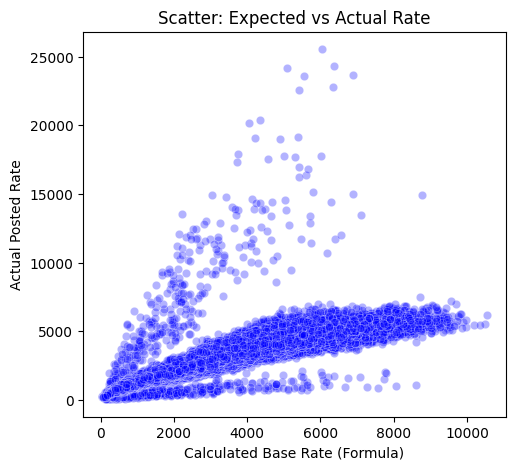

In [159]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(data=data, x='base_rate', y='posted_rate', alpha=0.3, color='blue')
plt.title("Scatter: Expected vs Actual Rate")
plt.xlabel("Calculated Base Rate (Formula)")
plt.ylabel("Actual Posted Rate")

In [158]:
Q1 = data['posted_rate'].quantile(0.25)
Q3 = data['posted_rate'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[(data['posted_rate'] < lower_bound) | (data['posted_rate'] > upper_bound)]

print(f"--- Outlier Detection Results ---")
print(f"Total rows in dataset: {len(data)}")
print(f"Upper limit boundary: ${upper_bound:.2f}")
print(f"Total outliers found: {len(outliers)}")
print(f"Percentage of dataset: {(len(outliers) / len(data)) * 100:.2f}%")

--- Outlier Detection Results ---
Total rows in dataset: 47038
Upper limit boundary: $6450.35
Total outliers found: 255
Percentage of dataset: 0.54%


In [89]:
#Linear Regression

In [165]:
data = pd.read_csv("train-test.csv")
data.dropna(inplace=True)
data = data.drop(['load_id','date','pickup','delivery'],axis = 1)
data = data.drop(data[data["weight"]<0].index)
data = pd.get_dummies(data, columns=["equipment"])
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
upper_limit = data['posted_rate'].quantile(0.99)
data = data[data['posted_rate'] <= upper_limit].copy()

In [170]:
from re import X
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
X = data.drop(["posted_rate", 'distance','quote_signal','market_index'], axis=1)
y = data["posted_rate"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [171]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [172]:
accuracy_score = r2_score(y_test, y_pred)
print(accuracy_score)

0.8757807758512357


In [117]:
pred = model.predict(X_test)

print("R²:", r2_score(y_test, pred))
print("MAE:", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))

R²: 0.7384814385829404
MAE: 357.6919550434393
RMSE: 769.1853355884801


Today 09-08-2026 We try XGboost and Randomforest

In [149]:
data = pd.read_csv("train-test.csv")
data.dropna(inplace=True)
data = pd.get_dummies(data, columns=["equipment"])
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
data = data.drop(data[data["weight"]<0].index)
data = data.drop(columns=['load_id','date', 'pickup', 'delivery','market_index', 'quote_signal','distance'],axis = 1)
upper_limit = data['posted_rate'].quantile(0.99)
data = data[data['posted_rate'] <= upper_limit].copy()

In [150]:
from sklearn.ensemble import RandomForestRegressor

X = data.drop(columns=['posted_rate'])
y = data['posted_rate']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [152]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [160]:
rf_preds = rf_model.predict(X_test)
print("R²:", r2_score(y_test, rf_preds))
print("MAE:", mean_absolute_error(y_test, rf_preds))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_preds)))

R²: 0.9532502688407916
MAE: 151.07414116383936
RMSE: 288.9853102935562


Trying with XG boost now

In [229]:
data = pd.read_csv("train-test.csv")
data.dropna(inplace=True)
data = data.drop(['load_id','date'],axis = 1)
data = pd.get_dummies(data, columns=["equipment"])
#data = data.drop(data[data["weight"]<0].index)
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
data  = data.drop(columns=['market_index', 'quote_signal','distance'],axis = 1)
upper_limit = data['posted_rate'].quantile(0.99)
data = data[data['posted_rate'] <= upper_limit].copy()

In [230]:
import xgboost as xgb
X,y = data.drop(['delivery','pickup','posted_rate'],axis = 1),data['posted_rate']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    tree_method='hist',
    device='cuda',
    random_state=42
    )
xgb_model.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [04:24:51] WARNING: /__w/xgboost/xgboost/src/context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [04:24:51] WARNING: /__w/xgboost/xgboost/src/context.cc:210: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device='cuda', early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [231]:
xgb_preds = xgb_model.predict(X_test)
print("R²:", r2_score(y_test, xgb_preds))
print("MAE:", mean_absolute_error(y_test, xgb_preds))

R²: 0.9610125698253194
MAE: 118.69913210430722


Since the accuracy on all classic models i used so far is low, will try new approach of catboost.


In [47]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.3 MB/s eta 0:00:00


In [48]:
from catboost import CatBoostRegressor

In [336]:
data = pd.read_csv("train-test.csv")
data.dropna(inplace=True)
data = data.drop(['load_id'],axis = 1)
#data = data.drop(data[data["weight"]<0].index)
data['month'] = pd.to_datetime(data['date']).dt.month
data['day'] = pd.to_datetime(data['date']).dt.day
data['year'] = pd.to_datetime(data['date']).dt.year
#data = pd.get_dummies(data, columns=["equipment"])
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
data  = data.drop(columns=['market_index', 'quote_signal','distance','date'],axis = 1)
upper_limit = data['posted_rate'].quantile(0.99)
data = data[data['posted_rate'] <= upper_limit].copy()

In [337]:
cat_features = ['pickup', 'delivery','equipment']

In [338]:
X,y = data.drop('posted_rate',axis = 1),data['posted_rate']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [343]:
cat_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    cat_features=cat_features,
    verbose=100
)

In [344]:
X.head()

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,equipment,weight,month,day,year,base_rate
0,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,Dry Van,30658.0,1,1,2025,628.843941
1,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,Reefer,17555.0,1,1,2025,666.385117
2,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,Dry Van,31721.0,1,1,2025,1802.841141
3,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,Dry Van,32333.0,1,1,2025,1712.828398
4,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,Reefer,35183.0,1,1,2025,1367.778577


In [345]:
cat_model.fit(X_train, y_train, eval_set=(X_test, y_test))

0:	learn: 1272.7668689	test: 1265.6488612	best: 1265.6488612 (0)	total: 59ms	remaining: 58.9s
100:	learn: 297.4856181	test: 299.4784359	best: 299.4784359 (100)	total: 2.92s	remaining: 26s
200:	learn: 269.0386613	test: 273.2977309	best: 273.2977309 (200)	total: 6.8s	remaining: 27s
300:	learn: 256.9110740	test: 264.0663077	best: 264.0663077 (300)	total: 9.69s	remaining: 22.5s
400:	learn: 249.8557011	test: 259.9218238	best: 259.9218238 (400)	total: 12.4s	remaining: 18.5s
500:	learn: 244.5053961	test: 257.1596987	best: 257.1596987 (500)	total: 15.1s	remaining: 15s
600:	learn: 240.4694198	test: 255.1978003	best: 255.1978003 (600)	total: 18.2s	remaining: 12.1s
700:	learn: 236.7501969	test: 253.6810115	best: 253.6810115 (700)	total: 22s	remaining: 9.37s
800:	learn: 233.6987277	test: 252.3490149	best: 252.3308700 (797)	total: 24.7s	remaining: 6.14s
900:	learn: 230.9133076	test: 251.5042893	best: 251.5042893 (900)	total: 27.4s	remaining: 3.01s
999:	learn: 228.3894568	test: 250.7713708	best: 250

CatBoostRegressor(cat_features=['pickup', 'delivery', 'equipment'], depth=6, iterations=1000, learning_rate=0.05, loss_function='RMSE', verbose=100)

In [346]:
cat_preds = cat_model.predict(X_test)

In [347]:
print("R²:", r2_score(y_test, cat_preds))
print("MAE:", mean_absolute_error(y_test, cat_preds))
print("RMSE:", np.sqrt(mean_squared_error(y_test, cat_preds)))

R²: 0.9639570005767296
MAE: 102.93327418497566
RMSE: 250.76197138136726


Checking which feature added the most in all the models

In [214]:
data = pd.read_csv("train-test.csv")
data.dropna(inplace=True)
data = data.drop(['load_id','date'],axis = 1)
data = data.drop(data[data["weight"]<0].index)
data = pd.get_dummies(data, columns=["equipment"])
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
data  = data.drop(columns=['market_index', 'quote_signal','distance'],axis = 1)
upper_limit = data['posted_rate'].quantile(0.99)
data = data[data['posted_rate'] <= upper_limit].copy()
X,y = data.drop(['delivery','pickup','posted_rate'],axis = 1),data['posted_rate']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
feature_names = X_train.columns
importance_df = pd.DataFrame({'Feature': feature_names})
importance_df['Random Forest'] = rf_model.feature_importances_

In [215]:
importance_df = importance_df.sort_values(by='Random Forest',ascending=False).reset_index(drop=True)

print("\n--- Relative Feature Importance Summary Table ---")
print(importance_df.to_string(index=False))


--- Relative Feature Importance Summary Table ---
          Feature  Random Forest
        base_rate       0.902008
       pickup_lon       0.031659
     delivery_lon       0.031549
           weight       0.012592
equipment_Dry Van       0.007845
     delivery_lat       0.006312
       pickup_lat       0.006149
 equipment_Reefer       0.001285
equipment_Flatbed       0.000601


In [232]:
data = pd.read_csv("train-test.csv")
data.dropna(inplace=True)
data = data.drop(['load_id','date'],axis = 1)
#data = data.drop(data[data["weight"]<0].index)
data = pd.get_dummies(data, columns=["equipment"])
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
data  = data.drop(columns=['market_index', 'quote_signal','distance'],axis = 1)
upper_limit = data['posted_rate'].quantile(0.99)
data = data[data['posted_rate'] <= upper_limit].copy()
X,y = data.drop(['delivery','pickup','posted_rate'],axis = 1),data['posted_rate']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
feature_names = X_train.columns
importance_df = pd.DataFrame({'Feature': feature_names})
importance_df['XGBoost'] = xgb_model.feature_importances_

In [233]:
importance_df = importance_df.sort_values(by='XGBoost',ascending=False).reset_index(drop=True)

print("\n--- Relative Feature Importance Summary Table ---")
print(importance_df.to_string(index=False))


--- Relative Feature Importance Summary Table ---
          Feature  XGBoost
        base_rate 0.808461
equipment_Dry Van 0.064942
     delivery_lon 0.036682
       pickup_lon 0.035060
 equipment_Reefer 0.027271
           weight 0.008604
     delivery_lat 0.007364
       pickup_lat 0.007139
equipment_Flatbed 0.004477


In [315]:
data = pd.read_csv("train-test.csv")
data.dropna(inplace=True)
data = data.drop(['load_id'],axis = 1)
#data = data.drop(data[data["weight"]<0].index)
data = pd.get_dummies(data, columns=["equipment"])
data['month'] = pd.to_datetime(data['date']).dt.month
data['day'] = pd.to_datetime(data['date']).dt.day
data['year'] = pd.to_datetime(data['date']).dt.year
data['base_rate'] = data['distance'] * data['market_index'] * data['quote_signal']
data  = data.drop(columns=['market_index', 'quote_signal','distance','date'],axis = 1)
upper_limit = data['posted_rate'].quantile(0.99)
data = data[data['posted_rate'] <= upper_limit].copy()
X,y = data.drop(['posted_rate'],axis = 1),data['posted_rate']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
feature_names = X_train.columns
importance_df = pd.DataFrame({'Feature': feature_names})
cat_importances = cat_model.get_feature_importance()
importance_df['CatBoost'] = cat_importances / np.sum(cat_importances)

In [316]:
importance_df = importance_df.sort_values(by='CatBoost',ascending=False).reset_index(drop=True)

print("\n--- Relative Feature Importance Summary Table ---")
print(importance_df.to_string(index=False))


--- Relative Feature Importance Summary Table ---
          Feature  CatBoost
        base_rate  0.669412
equipment_Dry Van  0.147153
       pickup_lon  0.054876
     delivery_lon  0.052429
            month  0.020953
             year  0.011717
           weight  0.010275
         delivery  0.007674
           pickup  0.007450
equipment_Flatbed  0.007429
       pickup_lat  0.005546
     delivery_lat  0.004711
              day  0.000376
 equipment_Reefer  0.000000


In [ ]:
Inference dataset

In [348]:
validation = pd.read_csv('validation.csv')

In [349]:
validation.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [350]:
validation_tp = pd.read_csv('validation-predictions-template.csv')

In [351]:
validation_tp.head()

,load_id,predicted_rate
0,TE-000001,NaN
1,TE-000002,NaN
2,TE-000003,NaN
3,TE-000004,NaN
4,TE-000005,NaN


Inference code

In [228]:
(validation['weight']<0).sum()

np.int64(145)

In [352]:
#validation = pd.get_dummies(validation, columns=["equipment"])
validation['month'] = pd.to_datetime(validation['date']).dt.month
validation['day'] = pd.to_datetime(validation['date']).dt.day
validation['year'] = pd.to_datetime(validation['date']).dt.year
validation['base_rate'] = validation['distance'] * validation['market_index'] * validation['quote_signal']
validation  = validation.drop(columns=['load_id','date','market_index', 'quote_signal','distance'],axis = 1)

In [371]:
validation

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,equipment,weight,month,day,year,base_rate
0,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,Flatbed,19958.0,11,1,2025,558.403962
1,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,Reefer,34114.0,11,1,2025,4160.938251
2,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,Dry Van,33435.0,11,1,2025,4903.300143
3,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,Dry Van,25392.0,11,1,2025,4326.668164
4,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,Flatbed,NaN,11,1,2025,1572.958136
...,...,...,...,...,...,...,...,...,...,...,...,...
11995,Fort Wayne,Louisville,41.31561,-85.36206,37.36588,-87.47153,Dry Van,38638.0,12,31,2025,842.764458
11996,Oklahoma City,Memphis,31.88294,-98.58097,35.56802,-89.52871,Dry Van,27685.0,12,31,2025,1739.494692
11997,Nashville,Montgomery,35.29479,-88.08915,31.37602,-86.10743,Flatbed,35522.0,12,31,2025,742.371621
11998,Syracuse,San Antonio,42.80915,-76.89973,29.50969,-98.40059,Dry Van,31755.0,12,31,2025,3522.152203


In [353]:
cat_preds = cat_model.predict(validation)

In [354]:
validation_tp['predicted_rate'] = cat_preds

In [355]:
validation_tp.head()

,load_id,predicted_rate
0,TE-000001,876.883086
1,TE-000002,4938.152166
2,TE-000003,4930.734205
3,TE-000004,3798.429445
4,TE-000005,1986.847307


In [356]:
validation_tp.to_csv("validation_predictions.csv", index=False)

from google.colab import files
files.download("validation_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [357]:
december = pd.read_csv('december-chart-inputs.csv')

In [358]:
data = pd.read_csv("train-test.csv")
data.dropna(inplace=True)

In [359]:
geography_lookup = data[['pickup', 'delivery', 'pickup_lat',
                             'pickup_lon', 'delivery_lat', 'delivery_lon']].drop_duplicates()

In [360]:
december = pd.merge(december, geography_lookup, on=['pickup', 'delivery'], how='left')

In [361]:
december['market_index'] = data['market_index'].median()
december['quote_signal'] = data['quote_signal'].median()
december['month'] = pd.to_datetime(december['date']).dt.month
december['day'] = pd.to_datetime(december['date']).dt.day
december['year'] = pd.to_datetime(december['date']).dt.year
december.drop(columns=['date'], inplace=True)

In [372]:
december = december[['pickup','delivery','pickup_lat','pickup_lon', 'delivery_lat', 'delivery_lon','equipment','weight','month','day','year','base_rate']]

In [373]:
december

,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,equipment,weight,month,day,year,base_rate
0,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,1,2025,781.390295
1,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,2,2025,781.390295
2,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,3,2025,781.390295
3,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,4,2025,781.390295
4,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,5,2025,781.390295
5,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,6,2025,781.390295
6,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,7,2025,781.390295
7,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,8,2025,781.390295
8,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,9,2025,781.390295
9,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,Dry Van,32000,12,10,2025,781.390295


In [363]:
december['base_rate'] = december['distance'] * december['market_index'] * december['quote_signal']

In [368]:
december.drop(columns=['predicted_rate'], inplace=True)

In [369]:
december

,pickup,delivery,equipment,weight,pickup_lat,pickup_lon,delivery_lat,delivery_lon,month,day,year,base_rate
0,Lexington,Fort Wayne,Dry Van,32000,36.99152,-84.99876,41.31561,-85.36206,12,1,2025,781.390295
1,Lexington,Fort Wayne,Dry Van,32000,36.99152,-84.99876,41.31561,-85.36206,12,2,2025,781.390295
2,Lexington,Fort Wayne,Dry Van,32000,36.99152,-84.99876,41.31561,-85.36206,12,3,2025,781.390295
3,Lexington,Fort Wayne,Dry Van,32000,36.99152,-84.99876,41.31561,-85.36206,12,4,2025,781.390295
4,Lexington,Fort Wayne,Dry Van,32000,36.99152,-84.99876,41.31561,-85.36206,12,5,2025,781.390295
5,Lexington,Fort Wayne,Dry Van,32000,36.99152,-84.99876,41.31561,-85.36206,12,6,2025,781.390295
6,Lexington,Fort Wayne,Dry Van,32000,36.99152,-84.99876,41.31561,-85.36206,12,7,2025,781.390295
7,Lexington,Fort Wayne,Dry Van,32000,36.99152,-84.99876,41.31561,-85.36206,12,8,2025,781.390295
8,Lexington,Fort Wayne,Dry Van,32000,36.99152,-84.99876,41.31561,-85.36206,12,9,2025,781.390295
9,Lexington,Fort Wayne,Dry Van,32000,36.99152,-84.99876,41.31561,-85.36206,12,10,2025,781.390295


In [375]:
dec_preds = cat_model.predict(december)

In [379]:
december = pd.read_csv('december-chart-inputs.csv')

In [380]:
december['predicted_rate'] = dec_preds

In [381]:
december

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,949.839156
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,945.500323
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,941.883735
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,947.493628
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,964.985076
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,968.209008
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,970.772359
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,971.450043
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,972.608104
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,972.870635


In [382]:
december.to_csv("december-chart-inputs.csv", index=False)

from google.colab import files
files.download("december-chart-inputs.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [384]:
cat_model.save_model('cat_model_l.cbm')